# EarthScape climate models

This notebook walks through the models in `train_models.py` using the data in MongoDB. It reads and displays only. Saving a new version is done by `python train_models.py` or the Retrain button on the dashboard.

In [1]:
import warnings
warnings.simplefilter('ignore')

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from pymongo import MongoClient

import train_models as tm

db = MongoClient(tm.MONGO_URI, serverSelectionTimeoutMS=5000)[tm.MONGO_DB]
rows = list(db.gistemp_zonal.find({'Glob': {'$ne': None}}, {'Year': 1, 'Glob': 1}).sort('Year', 1))
years = [row['Year'] for row in rows]
values = [row['Glob'] for row in rows]
print(len(years), 'years,', years[0], 'to', years[-1])

146 years, 1880 to 2025


## 1. Forecasting

Each method forecasts from many past years, using only what was known at the time. The lowest error on those earlier years picks the method. The last 10 years stay hidden until the end and are used once as the final test. The baseline, repeating the last value, is the score to beat and can't be chosen.

In [2]:
best, comparison = tm.evaluate_series(years, values)
print('Chosen:', best['label'])
print('Share of held-back years inside the 95% range:', best['test_coverage'])
pd.DataFrame(comparison)[['label', 'backtest_rmse', 'test_rmse', 'test_bias']]

Chosen: Linear trend, last 30 years
Share of held-back years inside the 95% range: 0.8


,label,backtest_rmse,test_rmse,test_bias
0,Last value (baseline),0.1566,0.1884,0.1230
1,"Linear trend, last 30 years",0.1298,0.1888,0.1486
2,"Linear trend, last 50 years",0.1625,0.1994,0.1614
3,Holt exponential smoothing,0.1392,0.2167,0.1720


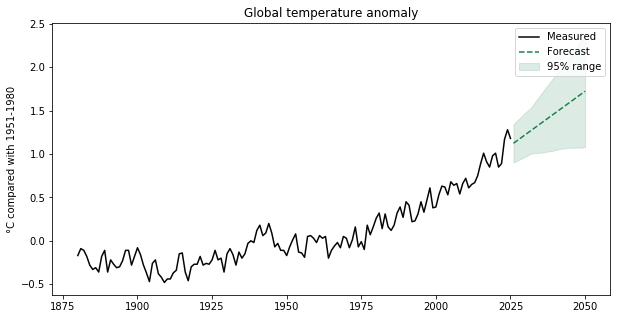

,forecast,lower,upper,year
4,1.224,0.970,1.478,2030
14,1.474,1.047,1.901,2040
24,1.724,1.080,2.368,2050


In [3]:
forecast = pd.DataFrame(tm.forecast_with_interval(years, values, best['method']))
plt.figure(figsize=(10, 5))
plt.plot(years, values, color='#040404', label='Measured')
plt.plot(forecast['year'], forecast['forecast'], color='#1a814a', linestyle='--', label='Forecast')
plt.fill_between(forecast['year'], forecast['lower'], forecast['upper'], color='#1a814a', alpha=0.15, label='95% range')
plt.ylabel('°C compared with 1951-1980')
plt.title('Global temperature anomaly')
plt.legend()
plt.show()
forecast[forecast['year'].isin([2030, 2040, 2050])]

This extends past temperatures forward using statistics. It isn't a climate model and knows nothing about future emissions.

## 2. Anomaly detection

An Isolation Forest scores daily air quality readings against the same sensor's previous 30 days. No one has labelled which days were truly abnormal, so it can't be given an ordinary accuracy score. Instead it trains on January to September, then we measure two things on October to December: how many ordinary days it flags, and how many artificial spikes it finds.

In [4]:
days = tm.read_sensor_days()
print(len(days), 'sensor days from', days.groupby(['location_id', 'parameter']).ngroups, 'sensor and pollutant pairs')
tm.injection_test(days)

6872 sensor days from 24 sensor and pollutant pairs


{'train_days': 4835,
 'test_days': 2037,
 'injected_days': 101,
 'false_alarm_rate': 0.0059,
 'recall_by_spike_size': {'3': 0.01, '6': 0.347, '10': 1.0}}

In [5]:
flagged = pd.DataFrame(list(db.ml_anomalies.find({}, {'_id': 0}).sort('score', -1)))
print(len(flagged), 'days flagged in the saved run')
flagged[['date', 'location', 'parameter', 'mean', 'max', 'z_mean', 'score']].head(10)

69 days flagged in the saved run


,date,location,parameter,mean,max,z_mean,score
0,2023-09-25,FR34024-4000,no,8.1130,85.2,23.47,0.845
1,2023-09-14,FR34024-4000,no,7.2250,47.4,20.90,0.842
2,2023-02-10,FR34024-4000,pm10,85.2292,146.7,8.97,0.835
3,2023-06-25,Presque Isle Riversi-1000,pm25,49.3750,102.2,9.17,0.832
4,2023-09-27,FR34024-4000,no,5.7286,42.2,15.95,0.831
5,2023-02-10,FR34024-4000,pm25,78.6500,139.4,8.78,0.831
6,2023-12-28,Presque Isle Riversi-1000,pm10,136.7391,490.0,8.90,0.829
7,2023-09-05,FR34024-4000,pm10,45.5333,110.3,6.15,0.825
8,2023-08-05,Spanish Springs-6001,pm10,76.7500,268.0,6.94,0.820
9,2023-09-28,FR34024-4000,no,4.1368,49.0,5.86,0.818


## 3. Correlation

Any two rising series correlate strongly, so CO2 and temperature are compared both as raw values and as year-to-year changes. Neither result proves cause.

In [6]:
pd.DataFrame(tm.correlations(db))[['left', 'right', 'kind', 'n', 'pearson', 'pearson_p', 'spearman']]

,left,right,kind,n,pearson,pearson_p,spearman
0,Atmospheric CO2,Global temperature anomaly,Raw yearly values,67,0.967,2.380000e-40,0.956
1,Yearly change in CO2,Yearly change in temperature anomaly,Year-to-year changes,66,0.316,9.690000e-03,0.299
2,"Station daily high, 24N-44N","MERRA-2 surface temperature, 24N-44N",Monthly values,24,0.975,7.400000e-16,0.957
3,"CERES solar radiation, 24N-44N","MERRA-2 surface temperature, 24N-44N",Monthly values,48,0.814,1.900000e-12,0.789
4,"Station daily high, 44N-64N","MERRA-2 surface temperature, 44N-64N",Monthly values,24,0.990,3.800000e-20,0.987
5,"CERES solar radiation, 44N-64N","MERRA-2 surface temperature, 44N-64N",Monthly values,48,0.730,3.920000e-09,0.729
6,"Station daily high, 44S-24S","MERRA-2 surface temperature, 44S-24S",Monthly values,24,0.934,2.630000e-11,0.929
7,"CERES solar radiation, 44S-24S","MERRA-2 surface temperature, 44S-24S",Monthly values,48,0.763,3.010000e-10,0.760
8,"Station daily high, 64S-44S","MERRA-2 surface temperature, 64S-44S",Monthly values,24,0.754,2.050000e-05,0.791
9,"CERES solar radiation, 64S-44S","MERRA-2 surface temperature, 64S-44S",Monthly values,48,0.312,3.080000e-02,0.326
